# Analysis AI-Team

### Load and import 

In [9]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

# --- General libraries --------------------------------------------------
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px          # interactive world map
import plotly.graph_objects as go    # confusion arcs, custom figures
from IPython.display import display
import torch

# --- Shared setup -------------------------------------------------------
from shared.data import Config, CountryMapper, OSV5MDataset, MetadataDecoder
from shared.models import (GeoCLIPModel, PredictionRunner, Segmenter, TextDetector,
                           Inpainter, fit_image, fit_mask, free_gpu_memory, get_device)
from shared.masking import MaskApplier
cfg = Config()

# --- Load groups own py files -------------------------------------------------------
# from pair_a.<file> import ...  


print("PyTorch", torch.__version__, "| CUDA build", torch.version.cuda)
device = get_device(cfg.device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    torch.cuda.reset_peak_memory_stats()
    
# ---------------- change settings here ----------------
cfg.images_per_country = 50
cfg.use_clip_baseline = False        # True -> downloads the original CLIP once (~1.7 GB)
cfg.crop_mode = "center_crop"        # "center_crop" | "pad" | "squash"
cfg.candidate_list = "v1"            # "v1" | "all_test_locations"
cfg.fill_mode = "gray"               # "gray" | "blur" | "inpaint" (inpaint downloads LaMa, ~200 MB)
cfg.batch_size = 32
cfg.num_workers = 4                  # set to 0 if image loading hangs (e.g. on Windows)
# ------------------------------------------------------

cfg.check()
cfg.show()

mapper = CountryMapper("resources/country_aliases.csv")
dataset = OSV5MDataset(cfg, mapper).load()      # no download, already on disk
decoder = MetadataDecoder()

run_name = f"streetclip_{cfg.candidate_list}_{cfg.crop_mode}"   # streetclip_v1_center_crop
preds, logits, embeds, info = PredictionRunner.load(f"results/shared/{run_name}")
preds = decoder.decode(preds)        # adds climate / land-cover / drive-side names

pilot_ids = dataset.build_pilot()    # loads the shared resources/pilot_ids.csv
print(f"{len(preds):,} predictions | {len(pilot_ids):,} pilot images | model: {info['model']}")

PyTorch 2.11.0+cu128 | CUDA build 12.8
GPU: NVIDIA GeForce RTX 4070 Ti SUPER
seed                   42
device                 auto
data_dir               data
results_dir            results
resources_dir          resources
images_per_country     50
streetclip_model       geolocal/StreetCLIP
use_clip_baseline      False
clip_model             openai/clip-vit-large-patch14-336
prompt_template        A Street View photo in {country}.
candidate_list         v1
crop_mode              center_crop
batch_size             32
num_workers            4
half_precision         True
top_k                  10
segmentation_model     facebook/mask2former-swin-large-mapillary-vistas-semantic
fill_mode              gray
blur_radius            25
mask_dilation_px       5
num_random_controls    3
lama_url               https://github.com/enesmsahin/simple-lama-inpainting/releases/download/v0.1.0/big-lama.pt
210,122 predictions | 9,578 pilot images | model: geolocal/StreetCLIP


## Q2: Overconfidence and training coverage
When is the model confidently wrong, and can we infer which countries were in its Street View training?

In [10]:
from pair_a import q2_confidence as q2

countries = mapper.table
clip_preds = pd.read_parquet("results/shared/clip_v1_center_crop/predictions.parquet")   # original CLIP

### Q2.1 Calibration
- Is the top-1 probability an honest estimate of the accuracy?
- StreetCLIP vs. original CLIP (same model before the Street View fine-tuning)

,n,conf,acc,ci_low,ci_high
prob_1,,,,,
"(-0.001, 0.1]",1899,0.081,0.066,0.056,0.078
"(0.1, 0.2]",19357,0.159,0.118,0.114,0.123
"(0.2, 0.3]",29053,0.250,0.198,0.194,0.203
"(0.3, 0.4]",27483,0.349,0.296,0.291,0.302
"(0.4, 0.5]",24592,0.450,0.409,0.403,0.416
"(0.5, 0.6]",20512,0.548,0.507,0.500,0.514
"(0.6, 0.7]",17477,0.649,0.617,0.609,0.624
"(0.7, 0.8]",17028,0.750,0.739,0.733,0.746
"(0.8, 0.9]",18541,0.851,0.824,0.818,0.829


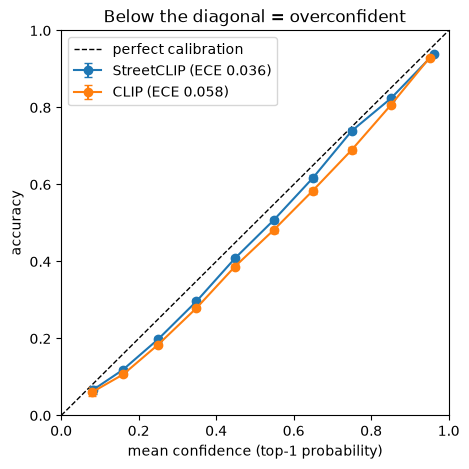

In [11]:
cal = {"StreetCLIP": q2.calibration_table(preds), "CLIP": q2.calibration_table(clip_preds)}
display(cal["StreetCLIP"].round(3))
q2.plot_reliability(cal);

### Q2.2 Where is the model confidently wrong?
- Per country: gap = mean confidence - accuracy (gap > 0: overconfident)
- Confident: top-1 probability >= 0.8

In [12]:
sc_table = q2.country_table(preds, countries)
display(sc_table[~sc_table.low_n].sort_values("gap", ascending=False).head(10).round(3))
q2.plot_gap_map(sc_table).show()

,n,acc,conf,conf_wrong,ci_low,ci_high,gap,name,iso3,in_train_list,low_n
country_id,,,,,,,,,,,
GE,290,0.000,0.366,0.021,0.000,0.013,0.366,Georgia,GEO,False,False
KW,33,0.030,0.378,0.000,0.005,0.153,0.348,Kuwait,KWT,False,False
EE,274,0.153,0.490,0.113,0.115,0.201,0.337,Estonia,EST,True,False
LT,131,0.023,0.351,0.000,0.008,0.065,0.328,Lithuania,LTU,True,False
ML,1226,0.006,0.323,0.011,0.003,0.012,0.317,Mali,MLI,False,False
SZ,35,0.086,0.400,0.057,0.030,0.224,0.314,Swaziland,SWZ,True,False
ZW,269,0.093,0.389,0.045,0.064,0.134,0.296,Zimbabwe,ZWE,False,False
YE,497,0.064,0.353,0.012,0.046,0.089,0.288,Yemen,YEM,False,False
MA,1266,0.094,0.382,0.013,0.079,0.111,0.288,Morocco,MAR,False,False


In [13]:
display(q2.confident_errors(preds, countries).round(3))

,country_id,pred_1,n,conf,share_of_errors,true_name,pred_name
524,US,GE,1126,0.909,0.127,United States,Georgia
522,US,CA,995,0.893,0.112,United States,Canada
116,CN,US,199,0.862,0.092,China,United States
204,GB,IE,105,0.910,0.183,United Kingdom,Ireland
239,IN,BD,83,0.907,0.033,India,Bangladesh
32,AU,NZ,70,0.911,0.078,Australia,New Zealand
372,NO,GL,69,0.905,0.085,Norway,Greenland
15,AR,CL,68,0.865,0.026,Argentina,Chile
166,ES,PT,67,0.875,0.053,Spain,Portugal
567,ZA,NA,64,0.841,0.036,South Africa,Namibia


- Low precision: a label the model picks often, but wrongly
- n_true = 0: country has no test images, so every prediction of it is an error

In [14]:
pred_table = q2.predicted_table(preds, countries)
display(pred_table[pred_table.n_pred >= 100].sort_values("precision").head(10).round(3))

,n_pred,precision,conf,n_true,name
pred_1,,,,,
GE,2436,0.000,0.717,290,Georgia
GA,740,0.000,0.210,7,Gabon
SY,793,0.000,0.458,1,Syria
NA,909,0.000,0.506,0,Namibia
GU,331,0.000,0.372,0,Guam
AD,196,0.000,0.432,0,Andorra
SM,187,0.000,0.445,0,San Marino
NR,286,0.000,0.317,0,Nauru
ER,169,0.000,0.322,13,Eritrea


### Q2.3 Training coverage
- Paper's training list: uncertain evidence (says 101 countries, lists 92)
- Idea: countries in the Street View training should gain most from fine-tuning (CLIP -> StreetCLIP)

In [15]:
display(q2.training_groups(sc_table).round(3))
gain = q2.gain_table(sc_table, q2.country_table(clip_preds, countries))
q2.plot_gain(gain).show()

,countries,images,macro_acc,macro_conf,mean_gap,acc_ci
in_train_list,,,,,,
False,85,48476,0.287,0.374,0.088,0.044
True,86,159576,0.468,0.515,0.047,0.053


In [16]:
big = gain[~gain.low_n]
display(big[~big.in_train_list].sort_values("gain", ascending=False).head(8).round(3))   # big gain, not in list
display(big[big.in_train_list].sort_values("gain").head(8).round(3))                     # in list, but no gain

,name,n,acc,in_train_list,low_n,acc_clip,gain
country_id,,,,,,,
SV,El Salvador,114,0.360,False,False,0.070,0.289
UZ,Uzbekistan,764,0.332,False,False,0.052,0.280
NE,Niger,260,0.462,False,False,0.185,0.277
TL,East Timor,213,0.282,False,False,0.038,0.244
GW,Guinea-Bissau,90,0.522,False,False,0.289,0.233
AO,Angola,1477,0.261,False,False,0.043,0.218
ET,Ethiopia,1937,0.330,False,False,0.161,0.169
KN,Saint Kitts and Nevis,60,0.633,False,False,0.483,0.150


,name,n,acc,in_train_list,low_n,acc_clip,gain
country_id,,,,,,,
FI,Finland,2280,0.626,True,False,0.918,-0.293
SI,Slovenia,73,0.123,True,False,0.370,-0.247
DO,Dominican Republic,165,0.048,True,False,0.273,-0.224
EE,Estonia,274,0.153,True,False,0.369,-0.215
UY,Uruguay,250,0.572,True,False,0.716,-0.144
UG,Uganda,837,0.250,True,False,0.393,-0.143
SZ,Swaziland,35,0.086,True,False,0.229,-0.143
LK,Sri Lanka,571,0.522,True,False,0.655,-0.133


## Q4: Environment
Do accuracy and confidence vary with climate, land cover, distance to the sea, or urban vs. rural setting?

In [17]:
from pair_a import q4_environment as q4

env = q4.add_env_columns(preds)   # adds climate_group, urban (built-up or not), sea_bin

### Q4.1 Land cover
- raw: pooled accuracy per class
- within-country: accuracy of the class minus the accuracy of its own country, averaged over countries
- raw and within-country disagree: the raw effect comes from the country mix (e.g. about half of "sparse vegetation" is Australia)

In [18]:
lc = q4.effect_table(env, "land_cover_name")
display(lc.round(3))
q4.plot_effects(lc, "Land cover: raw vs. within-country accuracy").show()

,n,countries,acc,conf,ci_low,ci_high,gap,low_n,w_countries,w_acc,w_conf,share_better,w_acc_ci
land_cover_name,,,,,,,,,,,,,
artificial surfaces,10392,136,0.605,0.620,0.596,0.614,0.015,False,74.0,0.067,0.046,0.730,0.032
bare soil,10745,81,0.334,0.452,0.325,0.343,0.118,False,44.0,-0.066,-0.014,0.364,0.046
cropland,71833,169,0.509,0.534,0.506,0.513,0.025,False,131.0,0.016,0.008,0.588,0.012
grassland,22977,152,0.494,0.525,0.487,0.500,0.031,False,88.0,-0.019,-0.002,0.364,0.022
"herbaceous, flooded",2639,52,0.556,0.621,0.537,0.575,0.064,False,16.0,-0.006,0.012,0.438,0.086
mangroves,191,29,0.429,0.401,0.361,0.500,-0.029,False,1.0,NaN,NaN,NaN,NaN
no data,34,7,0.412,0.543,0.264,0.578,0.131,False,NaN,NaN,NaN,NaN,NaN
shrubs,19622,110,0.443,0.503,0.436,0.450,0.060,False,64.0,-0.036,-0.008,0.391,0.026
snow and glaciers,91,8,0.758,0.729,0.661,0.835,-0.029,False,1.0,NaN,NaN,NaN,NaN


### Q4.2 Climate
- Köppen main groups (A tropical ... E polar)

In [19]:
cl = q4.effect_table(env, "climate_group")
display(cl.round(3))
q4.plot_effects(cl, "Climate: raw vs. within-country accuracy", order=list(q4.CLIMATE_GROUPS.values())).show()

,n,countries,acc,conf,ci_low,ci_high,gap,low_n,w_countries,w_acc,w_conf,share_better,w_acc_ci
climate_group,,,,,,,,,,,,,
A tropical,52436,99,0.382,0.412,0.378,0.386,0.030,False,86,-0.023,-0.018,0.291,0.021
B arid,52654,88,0.515,0.560,0.511,0.520,0.045,False,74,-0.008,0.001,0.405,0.023
C temperate,50087,100,0.526,0.586,0.522,0.530,0.060,False,81,-0.006,0.007,0.457,0.030
D continental,48590,60,0.612,0.622,0.608,0.616,0.010,False,46,-0.026,0.000,0.457,0.032
E polar,1876,27,0.631,0.674,0.609,0.652,0.043,False,12,-0.148,-0.016,0.250,0.103


### Q4.3 Distance to the sea
- `dist_sea`: 0 = at the coast, 1 = far inland (capped; landlocked countries have median 1.0)
- OSV-5M does not document the unit, so we use fixed bins

In [20]:
sea = q4.effect_table(env, "sea_bin")
display(sea.round(3))
q4.plot_effects(sea, "Distance to the sea: raw vs. within-country accuracy", order=q4.SEA_LABELS).show()

,n,countries,acc,conf,ci_low,ci_high,gap,low_n,w_countries,w_acc,w_conf,share_better,w_acc_ci
sea_bin,,,,,,,,,,,,,
0-0.05 (coast),24629,144,0.505,0.545,0.499,0.511,0.040,False,106,-0.018,-0.000,0.358,0.023
0.05-0.25,28153,136,0.534,0.549,0.529,0.540,0.014,False,107,0.006,-0.000,0.449,0.017
0.25-0.5,17831,116,0.519,0.545,0.511,0.526,0.026,False,90,-0.001,-0.006,0.511,0.026
0.5-0.9,28892,115,0.496,0.538,0.490,0.502,0.042,False,97,-0.009,-0.004,0.443,0.019
0.9-0.99,25827,92,0.511,0.560,0.505,0.517,0.048,False,80,-0.008,-0.007,0.525,0.030
0.99-1 (inland),82982,90,0.501,0.540,0.497,0.504,0.040,False,76,-0.000,0.004,0.474,0.020


### Q4.4 Urban vs. rural
- No urban column in OSV-5M. Proxy: land cover "artificial surfaces" (built-up area)
- `road_index` is not usable: it has only one value per country
- Check: one vote per camera sequence, so a long drive does not count many times

In [21]:
ur = q4.effect_table(env, "urban")
ur_seq = q4.effect_table(q4.per_sequence(env, "urban"), "urban")
display(pd.concat({"per image": ur, "per sequence": ur_seq}).round(3))

n  countries    acc   conf  ci_low  \
             urban                                                       
per image    rural / other     197888        188  0.503  0.540   0.501   
             urban (built-up)   10392        136  0.605  0.620   0.596   
per sequence rural / other      76233        188  0.515  0.546   0.511   
             urban (built-up)    6036        136  0.600  0.624   0.587   

                               ci_high    gap  low_n  w_countries  w_acc  \
             urban                                                         
per image    rural / other       0.505  0.038  False          171 -0.007   
             urban (built-up)    0.614  0.015  False           74  0.067   
per sequence rural / other       0.518  0.032  False          161 -0.007   
             urban (built-up)    0.612  0.024  False           52  0.083   

                               w_conf  share_better  w_acc_ci  
             urban                                             
per image    rural / other     -0.004         0.222     0.005  
             urban (built-up)   0.046         0.730     0.032  
per sequence rural / other     -0.004         0.255     0.003  
             urban (built-up)   0.056         0.788     0.030

In [22]:
urb = q4.urban_table(env, mapper.table)
display(urb.round(3).head(5))   # worse in built-up areas
display(urb.round(3).tail(5))   # better in built-up areas (check seq_urban: few sequences = weak evidence)
q4.plot_urban_map(urb).show()

,mean_rural,mean_urban,size_rural,size_urban,diff,seq_urban,name,iso3
country_id,,,,,,,,
PE,0.483,0.128,2075.0,39.0,-0.355,14,Peru,PER
BW,0.822,0.500,1761.0,26.0,-0.322,14,Botswana,BWA
PG,0.362,0.077,1520.0,26.0,-0.286,12,Papua New Guinea,PNG
AO,0.266,0.083,1441.0,36.0,-0.182,14,Angola,AGO
DZ,0.327,0.189,1507.0,148.0,-0.138,64,Algeria,DZA


,mean_rural,mean_urban,size_rural,size_urban,diff,seq_urban,name,iso3
country_id,,,,,,,,
EG,0.208,0.553,942.0,47.0,0.345,37,Egypt,EGY
SN,0.068,0.440,468.0,25.0,0.372,16,Senegal,SEN
CN,0.439,0.844,3640.0,762.0,0.405,301,China,CHN
AF,0.352,0.970,176.0,100.0,0.618,20,Afghanistan,AFG
LY,0.244,0.926,45.0,54.0,0.681,7,Libya,LBY


### Q4 findings
- **Climate:** raw accuracy differs a lot (A tropical 38 %, D continental 61 %). Inside a country the difference is almost gone: A to D are all within 3 points of 0. Only E polar is lower (-15 points), but with 12 countries and a wide CI. So the climate effect is mostly the country mix.
- **Land cover:** the same for most classes. "sparse vegetation" looks easy (72 %) only because about half of it is Australia. Real within-country effects: built-up +6.7 points, bare soil -6.6, tree covered -5.2.
- **Distance to the sea:** no effect, raw or within-country (all bins within 2 points of 0).
- **Urban vs. rural:** built-up areas are better than the country average in 73 % of 74 countries (+6.7 points). This also holds with one vote per camera sequence (+8.3 points, 52 countries). Very large values for single countries (Libya, Afghanistan) come from only a few sequences.
- **Confidence:** moves in the same direction as accuracy, but less (built-up: confidence +4.6 points, accuracy +6.7). Bare soil has the largest gap between confidence and accuracy (0.118, overconfident).
- `road_index` has one value per country, so it cannot measure urban vs. rural.
- Open question: does the urban advantage come from text and signs? The Q3 masking can test this.
